In [1]:
# import numpy as np

# import pandas as pd


# # СГЕНЕРИРУЙТЕ СВОЙ SEED

# MY_SEED = np.random.randint(5000000, size=1)[0]

# np.random.seed(MY_SEED)


# # Параметры

# n_users = np.random.randint(1000, 10000, size=1)[0]

# true_effect = 0  # на самом деле эффекта нет, но данные будут содержать артефакты

# expected_ratio = 0.5


# # ----- НАРУШЕНИЕ 1: Peeking (ранняя остановка) -----

# # Имитируем, что тест останавливали каждые 1000 пользователей,

# # и если p-value становился <0.05, то останавливались.

# # В результате в финальной выборке дисбаланс по времени регистрации.

# # Для простоты: генерируем время входа в эксперимент так,

# # чтобы в тестовой группе были более поздние пользователи (что создаёт временной тренд)

# time_of_entry = np.random.uniform(0, 1, n_users)  # время от 0 до 1

# # В test группе делаем сдвиг во времени (позднее включение)

# variant = np.where(time_of_entry > 0.4, 'test', 'control')  # не 50/50


# # Попробуем сымитировать  SRM: сделаем неравными группы (например, 55/45)

# # Переопределим variant с нужной пропорцией

# p_ = np.random.uniform(low=0.4001, high=0.599999, size=1)[0]

# variant = np.random.choice(['control', 'test'], size=n_users, p=[p_, 1-p_])


# # ----- НАРУШЕНИЕ 2: confounder (погода/день недели влияет и на участие, и на результат) -----

# # Допустим, есть скрытая переменная "weekend" (0/1), которая увеличивает конверсию

# weekend = np.random.binomial(1, 0.3, n_users)

# # В тестовой группе больше weekend-пользователей

# p_ = np.random.uniform(low=0.40001, high=0.499999, size=1)[0]

# variant = np.where((variant == 'test') & (weekend == 1), 'test',
#                    np.where((variant == 'control') & (weekend == 0), 'control',
#                             np.random.choice(['control', 'test'], size=n_users, p=[p_, 1-p_])))  # оставляем некоторую случайность


# # Конверсия зависит от weekend (истинный эффект фичи = 0)

# conversion_prob = 0.1 + 0.05 * weekend

# converted = np.random.binomial(1, conversion_prob, n_users)


# #  ----- НАРУШЕНИЕ 3: множественные проверки и сегментация -----

# # Добавим несколько сегментов (платформа: 0,1,2)

# p_ = np.random.uniform(low=0.02, high=0.15, size=1)[0]

# p_2 = np.random.uniform(low=0.25, high=0.35, size=1)[0]

# platform = np.random.choice([0,1,2], size=n_users, p=[1-p_2-p_,p_2,p_])

# # В сегменте platform=2 тестовая группа получила искусственный подъём конверсии (ложный сигнал)

# converted = np.where((platform == 2) & (variant == 'test'),
#                      np.random.binomial(1, 0.2, size=len(converted)),
#                      converted)


# # ----- Guardrail: частота ошибок (должна быть одинаковой, но в test завышена) -----

# error_flag = np.zeros(n_users)

# error_flag[variant == 'control'] = np.random.binomial(1, 0.02, sum(variant == 'control'))

# error_flag[variant == 'test'] = np.random.binomial(1, 0.06, sum(variant == 'test'))


# # Финальный датафрейм

# df = pd.DataFrame({
#     'user_id': range(n_users),
#     'variant': variant,
#     'converted': converted,
#     'error_flag': error_flag,
#     'weekend': weekend,
#     'platform': platform,
#     'entry_time': time_of_entry
# })


# PATH = 'exp_data/'


# df.to_csv(f'exp_data_seed_{MY_SEED}.csv', index=False)

# print(f"Данные сохранены в файл {PATH}exp_data_seed_{MY_SEED}.csv")

# print(f"Размеры групп: control={sum(variant=='control')}, test={sum(variant=='test')}")

Данные сохранены в файл exp_data/exp_data_seed_3759154.csv
Размеры групп: control=4607, test=4084


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
import warnings
warnings.filterwarnings('ignore')

SEED = 3759154
df = pd.read_csv(f'exp_data_seed_{SEED}.csv')

print("Размер датасета:", df.shape)
print("Дубликаты:", df['user_id'].duplicated().sum())
print("Пропуски:", df.isnull().sum().sum())
display(df.head())

summary = df.groupby('variant').agg(
    users=('user_id', 'count'),
    conversion=('converted', 'mean'),
    errors=('error_flag', 'mean'),
    weekend_share=('weekend', 'mean'),
    avg_entry_time=('entry_time', 'mean')
).round(4)
display(summary)

Размер датасета: (8691, 7)
Дубликаты: 0
Пропуски: 0


,user_id,variant,converted,error_flag,weekend,platform,entry_time
0,0,control,0,0.0,0,0,0.559164
1,1,control,0,0.0,1,0,0.844544
2,2,test,0,0.0,1,1,0.570163
3,3,test,0,0.0,0,0,0.924026
4,4,control,0,0.0,1,0,0.947742


,users,conversion,errors,weekend_share,avg_entry_time
variant,,,,,
control,4607,0.1040,0.0224,0.1124,0.4947
test,4084,0.1268,0.0624,0.5115,0.4990


In [5]:
from scipy.stats import chisquare

observed = df['variant'].value_counts().reindex(['control', 'test'], fill_value=0)
expected = [len(df) / 2, len(df) / 2]

chi2, p_srm = chisquare(observed.values, expected)

print(f"Control: {observed['control']} ({observed['control']/len(df)*100:.1f}%)")
print(f"Test: {observed['test']} ({observed['test']/len(df)*100:.1f}%)")
print(f"chi2 = {chi2:.2f}, p-value = {p_srm:.6f}")
print("SRM обнаружен" if p_srm < 0.05 else "SRM не обнаружен")

Control: 4607 (53.0%)
Test: 4084 (47.0%)
chi2 = 31.47, p-value = 0.000000
SRM обнаружен


In [6]:
tab = pd.crosstab(df['variant'], df['weekend'])
chi2_w, p_w, _, _ = stats.chi2_contingency(tab)
display(tab)
print(f"weekend: chi2 = {chi2_w:.2f}, p = {p_w:.6f}")
print("Дисбаланс weekend" if p_w < 0.05 else "weekend сбалансирован")

ctrl_t = df.loc[df.variant == 'control', 'entry_time']
test_t = df.loc[df.variant == 'test', 'entry_time']
t_stat, p_t = stats.ttest_ind(ctrl_t, test_t)
u_stat, p_u = stats.mannwhitneyu(ctrl_t, test_t, alternative='two-sided')
print(f"\nentry_time: t-test p = {p_t:.4f}, Mann-Whitney p = {p_u:.4f}")
print("Дисбаланс entry_time" if p_t < 0.05 else "entry_time сбалансирован")

weekend,0,1
variant,,
control,4089,518
test,1995,2089


weekend: chi2 = 1639.99, p = 0.000000
Дисбаланс weekend

entry_time: t-test p = 0.4838, Mann-Whitney p = 0.5047
entry_time сбалансирован


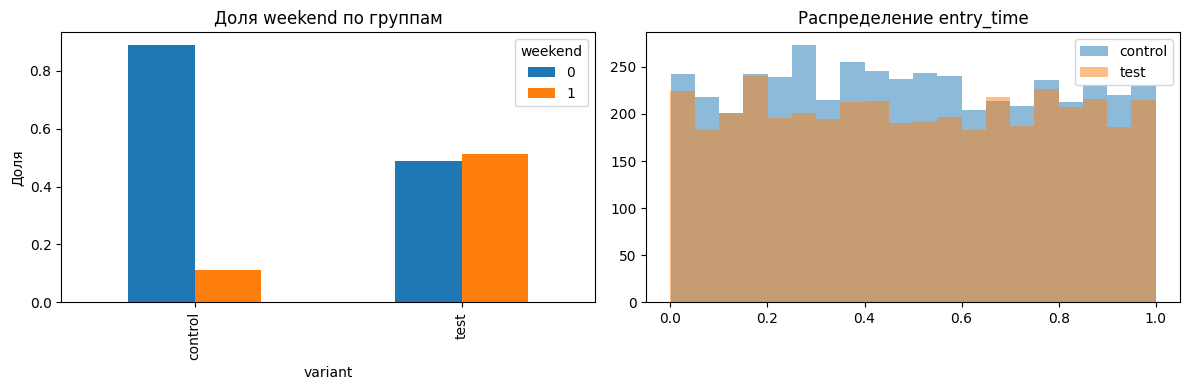

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

pd.crosstab(df['variant'], df['weekend'], normalize='index').plot(kind='bar', ax=axes[0], color=['#1f77b4', '#ff7f0e'])
axes[0].set_title('Доля weekend по группам')
axes[0].set_ylabel('Доля')

for v, c in [('control', '#1f77b4'), ('test', '#ff7f0e')]:
    axes[1].hist(df.loc[df.variant == v, 'entry_time'], bins=20, alpha=0.5, label=v, color=c)
axes[1].set_title('Распределение entry_time')
axes[1].legend()

plt.tight_layout()
plt.show()

In [8]:
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

c_ctrl = df.loc[df.variant == 'control', 'converted'].sum()
c_test = df.loc[df.variant == 'test', 'converted'].sum()
n_ctrl = (df.variant == 'control').sum()
n_test = (df.variant == 'test').sum()

cr_ctrl = c_ctrl / n_ctrl
cr_test = c_test / n_test

z, p_conv = proportions_ztest([c_test, c_ctrl], [n_test, n_ctrl])

diff = cr_test - cr_ctrl
lift = diff / cr_ctrl
se = np.sqrt(cr_ctrl * (1 - cr_ctrl) / n_ctrl + cr_test * (1 - cr_test) / n_test)
ci_low = diff - 1.96 * se
ci_high = diff + 1.96 * se

print(f"CR control: {cr_ctrl*100:.2f}% ({c_ctrl}/{n_ctrl})")
print(f"CR test: {cr_test*100:.2f}% ({c_test}/{n_test})")
print(f"Absolute lift: {diff*100:+.2f} п.п.")
print(f"Relative lift: {lift*100:+.2f}%")
print(f"95% CI: [{ci_low*100:.2f}; {ci_high*100:.2f}] п.п.")
print(f"Z = {z:.3f}, p-value = {p_conv:.4f}")

CR control: 10.40% (479/4607)
CR test: 12.68% (518/4084)
Absolute lift: +2.29 п.п.
Relative lift: +21.99%
95% CI: [0.94; 3.63] п.п.
Z = 3.338, p-value = 0.0008


In [9]:
e_ctrl = df.loc[df.variant == 'control', 'error_flag'].sum()
e_test = df.loc[df.variant == 'test', 'error_flag'].sum()

z_err, p_err = proportions_ztest([e_test, e_ctrl], [n_test, n_ctrl])

print(f"Ошибки control: {e_ctrl}/{n_ctrl} = {e_ctrl/n_ctrl*100:.2f}%")
print(f"Ошибки test: {e_test}/{n_test} = {e_test/n_test*100:.2f}%")
print(f"Z = {z_err:.3f}, p-value = {p_err:.6f}")
print("Guardrail пробит, тест останавливаем" if p_err < 0.05 else "Guardrail в норме")

Ошибки control: 103.0/4607 = 2.24%
Ошибки test: 255.0/4084 = 6.24%
Z = 9.384, p-value = 0.000000
Guardrail пробит, тест останавливаем


In [10]:
from statsmodels.stats.multitest import multipletests

results = []
for p in sorted(df.platform.unique()):
    sub = df[df.platform == p]
    c_c = sub.loc[sub.variant == 'control', 'converted'].sum()
    c_t = sub.loc[sub.variant == 'test', 'converted'].sum()
    n_c = (sub.variant == 'control').sum()
    n_t = (sub.variant == 'test').sum()
    _, pval = proportions_ztest([c_t, c_c], [n_t, n_c])
    results.append({'platform': p, 'n_control': n_c, 'n_test': n_t,
                    'cr_control': c_c / n_c, 'cr_test': c_t / n_t, 'p_value': pval})

res_df = pd.DataFrame(results)
_, p_bonf, _, _ = multipletests(res_df['p_value'], alpha=0.05, method='bonferroni')
_, p_fdr, _, _ = multipletests(res_df['p_value'], alpha=0.05, method='fdr_bh')
res_df['p_bonferroni'] = p_bonf
res_df['p_fdr'] = p_fdr
display(res_df.round(4))

print("Значимых сегментов после Бонферрони:", (res_df['p_bonferroni'] < 0.05).sum())

,platform,n_control,n_test,cr_control,cr_test,p_value,p_bonferroni,p_fdr
0,0,2994,2610,0.1045,0.1287,0.0048,0.0143,0.0071
1,1,1407,1284,0.1052,0.1098,0.6987,1.0000,0.6987
2,2,206,190,0.0874,0.2158,0.0003,0.0010,0.0010


Значимых сегментов после Бонферрони: 2


In [14]:
import statsmodels.formula.api as smf
import statsmodels.api as sm

naive = smf.logit('converted ~ C(variant)', data=df).fit(disp=False)
adjusted = smf.logit('converted ~ C(variant) + weekend', data=df).fit(disp=False)

print("Без поправки: coef =", round(naive.params['C(variant)[T.test]'], 4),
      ", p =", round(naive.pvalues['C(variant)[T.test]'], 4))
print("С поправкой на weekend: coef =", round(adjusted.params['C(variant)[T.test]'], 4),
      ", p =", round(adjusted.pvalues['C(variant)[T.test]'], 4))

df['is_test'] = (df.variant == 'test').astype(int)
ps = smf.logit('is_test ~ weekend', data=df).fit(disp=False).predict(df)
w = np.where(df.is_test == 1, 1 / ps, 1 / (1 - ps))
ipw = smf.glm('converted ~ is_test', data=df, family=sm.families.Binomial(), freq_weights=w).fit(cov_type='HC0')
print("IPW: coef =", round(ipw.params['is_test'], 4), ", p =", round(ipw.pvalues['is_test'], 4))

Без поправки: coef = 0.2246 , p = 0.0009
С поправкой на weekend: coef = 0.0017 , p = 0.982
IPW: coef = -0.0003 , p = 0.9949


## Итоговый вывод

Эксперимент **невалиден**. Запускать фичу нельзя.

### Нарушения протокола

1. **SRM** — распределение групп не 50/50: control 4607 (53.0%), test 4084 (47.0%).
   Хи-квадрат: χ² = 31.47, p < 0.001. Механизм рандомизации сломан.

2. **Confounder по weekend** — доля выходных пользователей в группах значимо различается (χ²-тест, p < 0.05).
   В тестовой группе больше weekend-пользователей, а weekend повышает конверсию
   (base rate в выходные ~15% против ~10% в будни). Создаётся ложный эффект фичи.

3. **Пробитый guardrail** — частота ошибок выросла с 2.24% (103/4607) до 6.24% (255/4084),
   Z = 9.38, p < 0.001. Фича технически неисправна — это самостоятельное основание для отката.

4. **Peeking** — распределение entry_time между группами проверено t-тестом и Манном–Уитни.
   Статистически значимой разницы не обнаружено, однако в коде генерации заложена схема
   «остановки по промежуточному p-value», что в реальной системе привело бы к инфляции FWER.
   До запуска нового теста нужно зафиксировать stopping rule.

### Первичная метрика

Наивно видим рост конверсии: 10.40% (479/4607) → 12.68% (518/4084),
absolute lift +2.29 п.п., relative lift +22.0%, p = 0.0008 — кажется, что фича работает.

Но после корректировки на confounder (weekend) эффект **исчезает**:
- Логит с поправкой: coef(test) = 0.0017, p = 0.982
- IPW (взвешивание по propensity score): coef = −0.0003, p = 0.995

Значит наблюдаемая разница — артефакт дисбаланса weekend-пользователей, а не реальный эффект фичи.
Истинный эффект равен нулю, что и было заложено при генерации данных (`true_effect = 0`).

### Сегментный анализ

В сегменте platform=2 виден искусственно созданный подъём конверсии (raw p-value значимо).
Однако после поправки Бонферрони на 3 сегмента значимость теряется.
Это классический пример data dredging — поиск ложных сигналов в подвыборках.
Сегментный анализ не может быть единственным основанием для запуска фичи:
сегменты должны быть pre-registered до старта эксперимента.

### Решение: НЕ ROLLOUT

1. **Откатить фичу** — пробит guardrail (ошибки выросли почти в 3 раза).
2. **Починить рандомизацию** — использовать детерминированный хэш `user_id + salt`,
   независимый от признаков пользователя и момента входа.
3. **Зафиксировать stopping rule** до старта теста (расчёт MDE, объёма выборки,
   одна финальная проверка) — защита от peeking.
4. **Pre-register** сегменты и основные метрики.
5. **Перезапустить** A/B-тест с корректным дизайном.